In [ ]:
pip install transformers torch scikit-learn pandas

In [3]:
import pandas as pd
from transformers import pipeline
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# create the sample file
df = pd.read_csv("employee_reviews.csv", encoding="latin-1").sample(100, random_state=42)
df["text"] = df[["summary", "pros", "cons"]].fillna("").agg(" ".join, axis=1)
df["label"] = df["overall-ratings"].map({1: "neg", 2: "neg", 3: "neu", 4: "pos", 5: "pos"})
df["classes"] = ""
df[["text","overall-ratings", "label", "cons", "classes" ]].to_csv("sample_100.csv", index=False)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cardiffnlp/twitter-roberta-base-sentiment-latest
  Accuracy: 0.71
  F1:       0.55


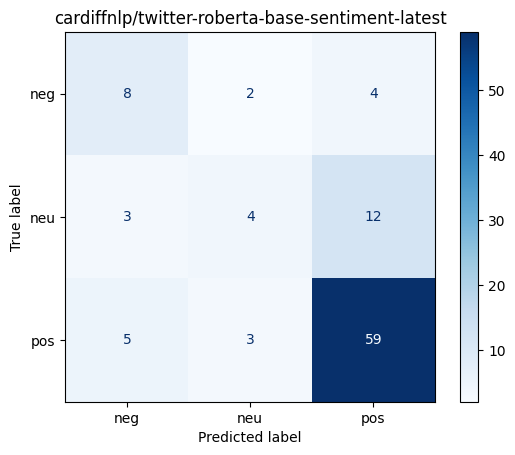

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

lxyuan/distilbert-base-multilingual-cased-sentiments-student
  Accuracy: 0.66
  F1:       0.408


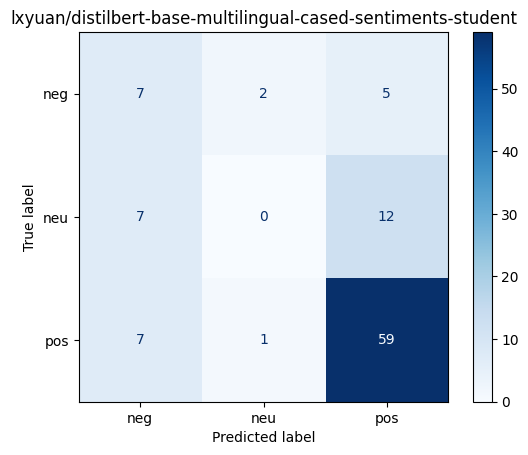

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0


finiteautomata/bertweet-base-sentiment-analysis
  Accuracy: 0.7
  F1:       0.555


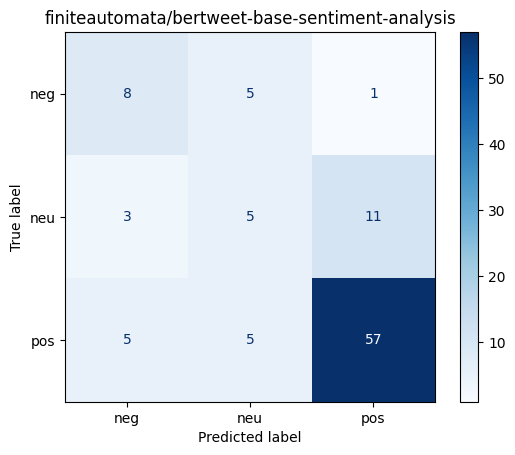

In [7]:
# Load it
df = pd.read_csv("sample_100.csv")
texts, ratings, labels, cons, classes = (df[c].tolist() for c in ["text", "overall-ratings", "label", "cons", "classes"])

models = ["cardiffnlp/twitter-roberta-base-sentiment-latest",
    "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "finiteautomata/bertweet-base-sentiment-analysis",]

for model in models:
    clf = pipeline("sentiment-analysis", model=model, truncation=True)
    preds = [o["label"][:3].lower() for o in clf(texts)]   # positive/POS -> "pos"
    print(model)
    # metrics
    print("  Accuracy:", round(accuracy_score(labels, preds), 3))
    print("  F1:      ", round(f1_score(labels, preds, average="macro"), 3))
    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(labels, preds, labels=["neg", "neu", "pos"], cmap="Blues")
    plt.title(model)
    plt.show()

In [8]:
# Incorrect predictions (first 100)
for text, true, pred in zip(texts, labels, preds):
    if true != pred:
        print(text[:80], "| true:", true, "| predicted:", pred)

Okay, depends on your division and director Amazing benefits, especially insuran | true: neg | predicted: neu
Microsoft Rules Flexibility and good benefits and good food Nothing. Everything  | true: neu | predicted: pos
Life@Microsoft Benefits Salary Brand Microsoft works on various technologies and | true: neg | predicted: neu
Good Company to work with its a good company to grow with it has a great technol | true: neu | predicted: pos
Money isn't everything. Extremely intelligent group of employees. Employees are  | true: neg | predicted: neu
Good 1st time Job Benefits starting from the 1st day Stress, you have to meet th | true: neu | predicted: pos
Fulfillment Associate Easy work Get benefit within first month of starting Manag | true: neg | predicted: neu
Data Scientist Perks and salary Good work/life balance Politics Too many re-orgs | true: pos | predicted: neu
They expect you to last less than 2 years Benefits are excellent, wide variety o | true: neu | predicted: neg
Great comp

config.json:   0%|          | 0.00/776 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/258 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Accuracy: 0.564
Macro F1: 0.523


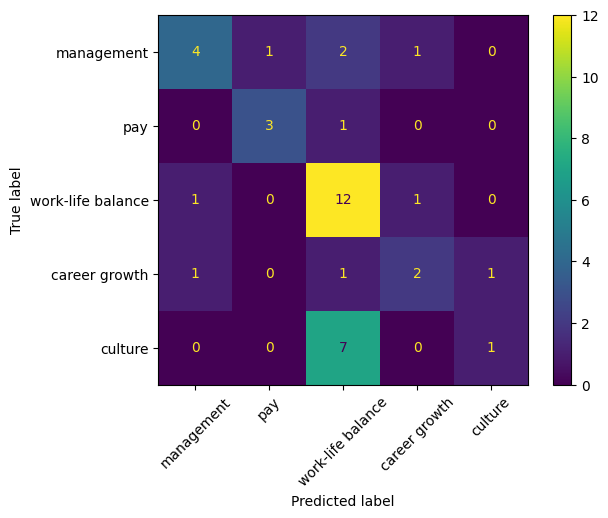

In [11]:
df = pd.read_csv("sample_100.csv").dropna(subset=["classes", "cons"])
issues = ["management", "pay", "work-life balance", "career growth", "culture"]
clf = pipeline("zero-shot-classification", model="typeform/distilbert-base-uncased-mnli")

true = df["classes"].tolist()
preds = [clf(t, candidate_labels=issues)["labels"][0] for t in df["cons"]]

print("Accuracy:", round(accuracy_score(true, preds), 3))
print("Macro F1:", round(f1_score(true, preds, average="macro"), 3))
ConfusionMatrixDisplay.from_predictions(true, preds, labels=issues, xticks_rotation=45);